# Fuente 2: CSV (`viviendas_pdtos.csv`)
## ETL Segunda Entrega · Notebook de la fuente "CSV"

Aquí trabajamos con el archivo "Viviendas (Departamental)" del DANE, que trae variables de la vivienda usadas para calcular el índice de pobreza multidimensional. Según el diccionario del DANE son 8 variables y 86.848 casos; el archivo que descargamos trae además la columna `DEPARTAMENTO` y 87.060 filas.

Variables del diccionario:
- `DIRECTORIO`, `SECUENCIA_ENCUESTA` y `SECUENCIA_P`: identifican la vivienda y el hogar.
- `P3`: clase.
- `P4005`: material predominante de las paredes exteriores.
- `P4015`: material predominante de los pisos.
- `P8520S3`: alcantarillado.
- `P8520S5`: acueducto.

El significado de cada código (por ejemplo, 1 = "Sí" y 2 = "No") lo tomamos del diccionario del DANE y lo dejamos en `ETIQUETAS` y `VALORES_VALIDOS` (Paso 1). Lo usamos para ponerle nombre a las categorías en las tablas y para validar que solo lleguen códigos permitidos.

**Pasos del notebook**
1. Leer el CSV desde Drive (o subirlo si no está).
2. Revisar los datos crudos (EDA): tipos, nulos, duplicados, llaves, distribución de cada variable y relación entre variables.
3. Limpiar y transformar.
4. Comparar con la fuente del IPM (si el notebook 01 ya se ejecutó): qué porcentaje de hogares coincide y cómo se relacionan las variables con la pobreza.
5. Validar con Great Expectations y guardar el resultado para el merge.

## Paso 0: Instalar las librerías

In [1]:
!pip install -q "great-expectations>=1.0,<2" pandas pyarrow scipy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 36.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.2/49.2 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 3.7 MB/s eta 0:00:00


## Paso 1: Configuración

Antes de ejecutar hay que subir `viviendas_pdtos.csv` a la carpeta `Colab Notebooks/etl_proyecto` de Drive. Si no está ahí, el Paso 2 abre un cuadro para subirlo.

In [2]:
import io, os, json, contextlib, warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

# en Colab guardamos en Drive; fuera de Colab, en una carpeta local
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/My Drive/Colab Notebooks/etl_proyecto"
except Exception:
    BASE = "./etl_proyecto"

INTERMEDIOS = f"{BASE}/staging"
REPORTES = f"{BASE}/reports"
for carpeta in (INTERMEDIOS, REPORTES):
    os.makedirs(carpeta, exist_ok=True)

CSV_NOMBRE = "viviendas_pdtos.csv"
CSV_PATH = os.environ.get("CSV_PATH", f"{BASE}/{CSV_NOMBRE}")

# nombre de cada variable según el diccionario del DANE
DESCRIPCIONES = {
    "p3": "Clase",
    "p4005": "Material predominante de las paredes exteriores",
    "p4015": "Material predominante de los pisos",
    "p8520s3": "Alcantarillado",
    "p8520s5": "Acueducto",
}

# nombres nuevos de las columnas; usamos "_vivienda" para no chocar con los indicadores del IPM
# (la fuente del IPM ya tiene columnas acueducto, alcantarillado, pisos y paredes)
RENOMBRAR = {
    "p3": "clase",
    "p4005": "material_paredes",
    "p4015": "material_pisos",
    "p8520s3": "alcantarillado_vivienda",
    "p8520s5": "acueducto_vivienda",
}

# significado de cada código, según el diccionario del DANE
ETIQUETAS = {
    "clase": {1: "Cabecera", 2: "Centro poblado", 3: "Rural disperso"},
    "material_paredes": {
        1: "Bloque, ladrillo, piedra, madera pulida", 2: "Tapia pisada, adobe",
        3: "Bahareque revocado", 4: "Bahareque sin revocar", 5: "Madera burda, tabla, tablón",
        6: "Material prefabricado", 7: "Guadua, caña, esterilla, otro vegetal",
        8: "Zinc, tela, carbón, latas, desechos, plástico", 9: "Sin paredes",
    },
    "material_pisos": {
        1: "Alfombra o tapete de pared a pared", 2: "Madera pulida y lacada, parqué", 3: "Mármol",
        4: "Baldosa, vinilo, tableta, ladrillo", 5: "Madera burda, tabla, tablón, otro vegetal",
        6: "Cemento, gravilla", 7: "Tierra, arena",
    },
    "alcantarillado_vivienda": {1: "Sí", 2: "No"},
    "acueducto_vivienda": {1: "Sí", 2: "No"},
}

# códigos permitidos (los mismos del diccionario)
VALORES_VALIDOS = {
    "clase": [1, 2, 3],
    "material_paredes": list(range(1, 10)),
    "material_pisos": list(range(1, 8)),
    "alcantarillado_vivienda": [1, 2],
    "acueducto_vivienda": [1, 2],
}

INVERSO = {nuevo: viejo for viejo, nuevo in RENOMBRAR.items()}


def descripcion(col):
    # texto del diccionario para una columna, con el nombre original o el nuevo
    return DESCRIPCIONES.get(col.lower()) or DESCRIPCIONES.get(INVERSO.get(col, ""), col)

print("CSV:", CSV_PATH)
print("Salidas en:", BASE)

Mounted at /content/drive
CSV: /content/drive/My Drive/Colab Notebooks/etl_proyecto/viviendas_pdtos.csv
Salidas en: /content/drive/My Drive/Colab Notebooks/etl_proyecto


## Paso 2: Lectura (`read_csv`)

Si el archivo no está en la ruta, en Colab se abre un cuadro para subirlo. Leemos los valores `NA` y los vacíos como nulos, y si el archivo no viene en UTF-8 probamos con `latin-1`.

In [3]:
def read_csv(path=CSV_PATH):
    if not os.path.exists(path):
        try:
            from google.colab import files
            print("El archivo no está en Drive. Subirlo ahora:")
            subido = files.upload()
            path = next(iter(subido))
        except ImportError:
            raise FileNotFoundError(f"No existe {path}")
    try:
        df = pd.read_csv(path, na_values=["NA", ""], low_memory=False)
    except UnicodeDecodeError:
        df = pd.read_csv(path, na_values=["NA", ""], low_memory=False, encoding="latin-1")
    print(f"[read_csv] {len(df):,} filas x {df.shape[1]} columnas")
    return df

In [4]:
df_raw = read_csv()

[read_csv] 87,060 filas x 9 columnas


In [5]:
# copia de los datos crudos para usarlos desde otros notebooks
df_raw.to_parquet(f"{INTERMEDIOS}/csv_raw.parquet", index=False)
df_raw.head()

,DIRECTORIO,SECUENCIA_ENCUESTA,SECUENCIA_P,P3,P4005,P4015,P8520S3,P8520S5,DEPARTAMENTO
0,8369550,4,1,1,1,4,1,1,13
1,8369551,1,1,1,1,4,1,1,13
2,8369552,5,1,1,1,6,1,1,13
3,8369553,3,1,1,1,6,1,1,13
4,8369554,2,1,1,1,4,1,1,13


## Paso 3: EDA sobre los datos crudos

Mostramos una sola cosa por celda para que sea fácil de leer.

In [6]:
print("Filas y columnas:", df_raw.shape)

Filas y columnas: (87060, 9)


In [7]:
df_raw.dtypes.to_frame("tipo")

,tipo
DIRECTORIO,int64
SECUENCIA_ENCUESTA,int64
SECUENCIA_P,int64
P3,int64
P4005,int64
P4015,int64
P8520S3,int64
P8520S5,int64
DEPARTAMENTO,int64


In [8]:
nulos = df_raw.isnull().sum()
nulos[nulos > 0].to_frame("nulos") if (nulos > 0).any() else "Sin nulos"

'Sin nulos'

In [9]:
print("Duplicados exactos:", df_raw.duplicated().sum())

Duplicados exactos: 212


In [10]:
# llave del hogar: directorio + secuencia_p
cols_min = {c.lower(): c for c in df_raw.columns}
llave_raw = [cols_min[c] for c in ("directorio", "secuencia_p") if c in cols_min]
print(f"Duplicados por llave {llave_raw}:", df_raw.duplicated(subset=llave_raw).sum() if llave_raw else "no hay llave")

Duplicados por llave ['DIRECTORIO', 'SECUENCIA_P']: 212


In [11]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
DIRECTORIO,87060.0,8426910.71,33355.82,8369550.0,8399685.75,8423755.5,8456464.25,8489522.0
SECUENCIA_ENCUESTA,87060.0,2.71,1.44,1.0,2.00,2.0,4.00,21.0
SECUENCIA_P,87060.0,1.01,0.10,1.0,1.00,1.0,1.00,6.0
P3,87060.0,1.83,0.91,1.0,1.00,1.0,3.00,3.0
P4005,87060.0,1.86,1.74,1.0,1.00,1.0,1.00,10.0
P4015,87060.0,5.06,1.14,1.0,4.00,5.0,6.00,7.0
P8520S3,87060.0,1.50,0.50,1.0,1.00,1.0,2.00,2.0
P8520S5,87060.0,1.25,0.44,1.0,1.00,1.0,2.00,2.0
DEPARTAMENTO,87060.0,48.38,30.03,5.0,19.00,50.0,73.00,99.0


### Distribución de cada variable

Las columnas que no son llave son códigos. Mostramos cuántos hogares hay por código, en porcentaje, con una gráfica. Una variable por celda.

In [12]:
SIN_VARIABLE = ("directorio", "secuencia_p", "secuencia_encuesta")
variables = [c for c in df_raw.columns if c.lower() not in SIN_VARIABLE]
print("Variables del cuestionario:", variables)

Variables del cuestionario: ['P3', 'P4005', 'P4015', 'P8520S3', 'P8520S5', 'DEPARTAMENTO']


In [13]:
def distribucion(nombre):
    # busca la columna sin importar mayúsculas y muestra la tabla por código y una gráfica
    col = next((c for c in df_raw.columns if c.lower() == nombre.lower()), None)
    if col is None:
        print(f"La columna {nombre} no existe en el CSV")
        return
    mapa = ETIQUETAS.get(RENOMBRAR.get(nombre.lower(), ""), {})
    vc = df_raw[col].value_counts(dropna=False).sort_index()
    tabla = pd.DataFrame({"categoria": [mapa.get(k, "") for k in vc.index],
                          "hogares": vc.values,
                          "porcentaje": (vc / len(df_raw) * 100).round(1).values}, index=vc.index)
    print(f"{col} ({descripcion(col)}): {df_raw[col].nunique()} valores distintos")
    print(tabla.to_string())

    plt.figure(figsize=(6, 3.2))
    vc.plot(kind="bar", color="#2980b9")
    plt.title(f"Hogares por código: {descripcion(col)}")
    plt.xlabel("Código"); plt.ylabel("Hogares")
    plt.savefig(f"{REPORTES}/eda_csv_{nombre.lower()}.png", dpi=120, bbox_inches="tight")
    plt.show()

P3 (Clase): 3 valores distintos
         categoria  hogares  porcentaje
P3                                     
1         Cabecera    44351        50.9
2   Centro poblado    12891        14.8
3   Rural disperso    29818        34.2


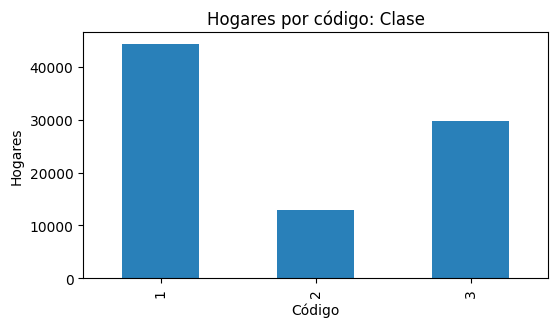

In [14]:
distribucion("p3")

P4005 (Material predominante de las paredes exteriores): 10 valores distintos
                                           categoria  hogares  porcentaje
P4005                                                                    
1            Bloque, ladrillo, piedra, madera pulida    67242        77.2
2                                Tapia pisada, adobe     1422         1.6
3                                 Bahareque revocado     2403         2.8
4                              Bahareque sin revocar     2284         2.6
5                        Madera burda, tabla, tablón    11454        13.2
6                              Material prefabricado      606         0.7
7              Guadua, caña, esterilla, otro vegetal       96         0.1
8      Zinc, tela, carbón, latas, desechos, plástico      497         0.6
9                                        Sin paredes      948         1.1
10                                                        108         0.1


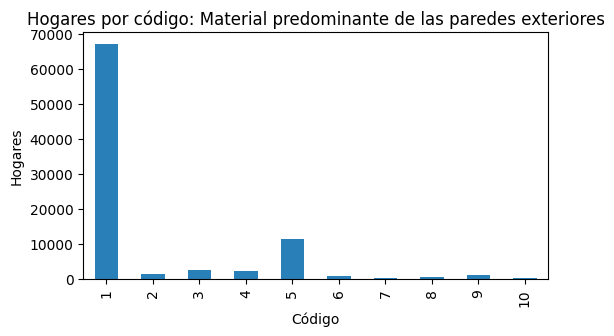

In [15]:
distribucion("p4005")

P4015 (Material predominante de los pisos): 7 valores distintos
                                       categoria  hogares  porcentaje
P4015                                                                
1             Alfombra o tapete de pared a pared      166         0.2
2                 Madera pulida y lacada, parqué      537         0.6
3                                         Mármol      164         0.2
4             Baldosa, vinilo, tableta, ladrillo    40395        46.4
5      Madera burda, tabla, tablón, otro vegetal     5360         6.2
6                              Cemento, gravilla    32508        37.3
7                                  Tierra, arena     7930         9.1


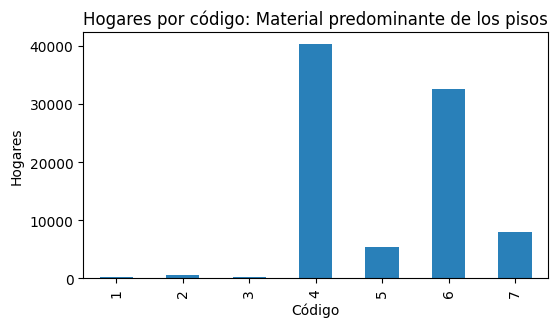

In [16]:
distribucion("p4015")

P8520S3 (Alcantarillado): 2 valores distintos
        categoria  hogares  porcentaje
P8520S3                               
1              Sí    43912        50.4
2              No    43148        49.6


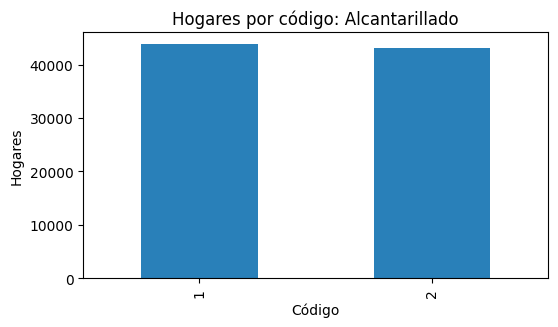

In [17]:
distribucion("p8520s3")

P8520S5 (Acueducto): 2 valores distintos
        categoria  hogares  porcentaje
P8520S5                               
1              Sí    64913        74.6
2              No    22147        25.4


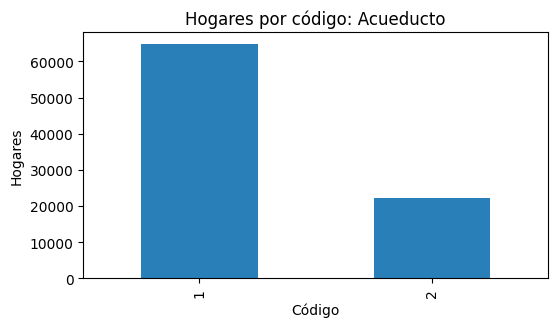

In [18]:
distribucion("p8520s5")

### Relación entre variables

Usamos la V de Cramér, que va de 0 (no hay relación) a 1 (relación total). La escogimos porque todas las variables son categóricas. Por ejemplo, `clase` y alcantarillado salen bastante relacionadas (0,74).

In [19]:
def cramers_v(a, b):
    t = pd.crosstab(a, b)
    if t.shape[0] < 2 or t.shape[1] < 2:
        return np.nan
    chi2 = chi2_contingency(t)[0]
    return float(np.sqrt((chi2 / t.values.sum()) / (min(t.shape) - 1)))


cat = [c for c in variables if df_raw[c].nunique() <= 20]
V = pd.DataFrame({b: {a: cramers_v(df_raw[a], df_raw[b]) for a in cat} for b in cat})
V.round(2)

,P3,P4005,P4015,P8520S3,P8520S5
P3,1.00,0.27,0.32,0.74,0.48
P4005,0.27,1.00,0.33,0.40,0.46
P4015,0.32,0.33,1.00,0.49,0.46
P8520S3,0.74,0.40,0.49,1.00,0.51
P8520S5,0.48,0.46,0.46,0.51,1.00


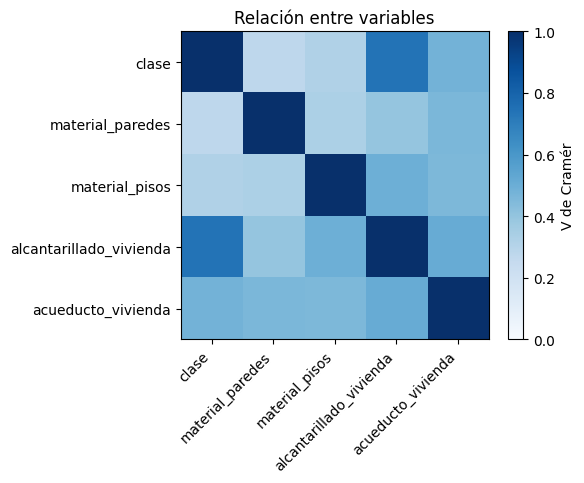

In [20]:
plt.figure(figsize=(5, 4))
plt.imshow(V.values.astype(float), cmap="Blues", vmin=0, vmax=1)
nombres = [RENOMBRAR.get(c.lower(), c) for c in cat]
plt.xticks(range(len(cat)), nombres, rotation=45, ha="right")
plt.yticks(range(len(cat)), nombres)
plt.colorbar(label="V de Cramér")
plt.title("Relación entre variables")
plt.savefig(f"{REPORTES}/eda_csv_asociacion.png", dpi=120, bbox_inches="tight")
plt.show()

## Paso 4: Transformación (`transform_csv`)

Decisiones que tomamos (quedan para el informe):
1. Pasamos los nombres de columnas a minúscula y aplicamos `RENOMBRAR`.
2. Convertimos las columnas a número. Si todos sus valores son enteros quedan como entero (que admite nulos). Si algún valor no es numérico pasa a nulo y avisamos cuántos fueron.
3. Eliminamos las filas completamente duplicadas (212).
4. Si quedan hogares con la misma llave pero valores distintos, solo avisamos. No los borramos porque esa decisión la tiene que tomar el equipo.
5. Creamos `codigo_departamento` (2 dígitos) y `nombre_departamento`.
6. Creamos `id_hogar` con el formato `directorio-secuencia_p`. Es la llave para cruzar con las otras fuentes.
7. Agregamos una columna `<variable>_desc` con el texto de cada código (`ETIQUETAS`) y conservamos el código original.

In [21]:
DEPARTAMENTOS = {
      "05": "Antioquia", "08": "Atlántico", "11": "Bogotá D.C.", "13": "Bolívar",
      "15": "Boyacá", "17": "Caldas", "18": "Caquetá", "19": "Cauca", "20": "Cesar",
      "23": "Córdoba", "25": "Cundinamarca", "27": "Chocó", "41": "Huila",
      "44": "La Guajira", "47": "Magdalena", "50": "Meta", "52": "Nariño",
      "54": "Norte de Santander", "63": "Quindío", "66": "Risaralda",
      "68": "Santander", "70": "Sucre", "73": "Tolima", "76": "Valle del Cauca",
      "81": "Arauca", "85": "Casanare", "86": "Putumayo",
      "88": "San Andrés y Providencia", "91": "Amazonas", "94": "Guainía",
      "95": "Guaviare", "97": "Vaupés", "99": "Vichada",
    }


def transform_csv(df_raw):

    df = df_raw.copy()
    df.columns = [c.strip().lower() for c in df.columns]

    for c in df.columns:
        antes = df[c].notna().sum()
        num = pd.to_numeric(df[c], errors="coerce")
        perdidos = antes - num.notna().sum()
        if perdidos:
            print(f"[transform_csv] {c}: {perdidos:,} valores no numéricos pasaron a nulo")
        es_entero = (num.dropna() % 1 == 0).all()
        df[c] = num.astype("Int64") if es_entero else num

    n0 = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"[transform_csv] duplicados exactos eliminados: {n0 - len(df):,}")



    dep = df["departamento"].astype("Int64")
    df["codigo_departamento"] = dep.astype(str).str.zfill(2).where(dep.notna())
    df["nombre_departamento"] = df["codigo_departamento"].map(DEPARTAMENTOS)
    sin_nombre = df["nombre_departamento"].isna().sum()
    if sin_nombre:
        print(f"[transform_csv] Ojo: {sin_nombre:,} filas tienen un departamento que no está en el catálogo")


    llave = [c for c in ("directorio", "secuencia_p") if c in df.columns]
    if len(llave) == 2:
        rep = df.duplicated(subset=llave, keep=False).sum()
        if rep:
            print(f"[transform_csv] {rep:,} filas comparten la llave {llave} con valores distintos")
        df["id_hogar"] = df["directorio"].astype(str) + "-" + df["secuencia_p"].astype(str)

    df = df.rename(columns=RENOMBRAR)
    for col, mapa in ETIQUETAS.items():
        if col in df.columns:
            df[col + "_desc"] = df[col].map(mapa)

    print(f"[transform_csv] resultado: {df.shape[0]:,} filas x {df.shape[1]} columnas")
    return df

In [22]:
df = transform_csv(df_raw)

[transform_csv] duplicados exactos eliminados: 212
[transform_csv] resultado: 86,848 filas x 17 columnas


In [23]:
df.head(50)

,directorio,secuencia_encuesta,secuencia_p,clase,material_paredes,material_pisos,alcantarillado_vivienda,acueducto_vivienda,departamento,codigo_departamento,nombre_departamento,id_hogar,clase_desc,material_paredes_desc,material_pisos_desc,alcantarillado_vivienda_desc,acueducto_vivienda_desc
0,8369550,4,1,1,1,4,1,1,13,13,Bolívar,8369550-1,Cabecera,"Bloque, ladrillo, piedra, madera pulida","Baldosa, vinilo, tableta, ladrillo",Sí,Sí
1,8369551,1,1,1,1,4,1,1,13,13,Bolívar,8369551-1,Cabecera,"Bloque, ladrillo, piedra, madera pulida","Baldosa, vinilo, tableta, ladrillo",Sí,Sí
2,8369552,5,1,1,1,6,1,1,13,13,Bolívar,8369552-1,Cabecera,"Bloque, ladrillo, piedra, madera pulida","Cemento, gravilla",Sí,Sí
3,8369553,3,1,1,1,6,1,1,13,13,Bolívar,8369553-1,Cabecera,"Bloque, ladrillo, piedra, madera pulida","Cemento, gravilla",Sí,Sí
4,8369554,2,1,1,1,4,1,1,13,13,Bolívar,8369554-1,Cabecera,"Bloque, ladrillo, piedra, madera pulida","Baldosa, vinilo, tableta, ladrillo",Sí,Sí
5,8369555,2,1,1,1,4,1,1,13,13,Bolívar,8369555-1,Cabecera,"Bloque, ladrillo, piedra, madera pulida","Baldosa, vinilo, tableta, ladrillo",Sí,Sí
6,8369557,3,1,1,1,4,1,1,13,13,Bolívar,8369557-1,Cabecera,"Bloque, ladrillo, piedra, madera pulida","Baldosa, vinilo, tableta, ladrillo",Sí,Sí
7,8369558,3,1,1,1,4,1,1,13,13,Bolívar,8369558-1,Cabecera,"Bloque, ladrillo, piedra, madera pulida","Baldosa, vinilo, tableta, ladrillo",Sí,Sí
8,8369559,4,1,1,1,4,1,1,13,13,Bolívar,8369559-1,Cabecera,"Bloque, ladrillo, piedra, madera pulida","Baldosa, vinilo, tableta, ladrillo",Sí,Sí
9,8369560,5,1,1,1,4,1,1,13,13,Bolívar,8369560-1,Cabecera,"Bloque, ladrillo, piedra, madera pulida","Baldosa, vinilo, tableta, ladrillo",Sí,Sí


### Privación de acueducto por departamento
Con el CSV ya limpio calculamos el porcentaje de hogares sin acueducto en la vivienda (`acueducto_vivienda = 2`) por departamento. Es un primer ejemplo de indicador por departamento que después podemos cruzar con el IPM.

In [24]:
vvnds_acue = df[['codigo_departamento', 'acueducto_vivienda', 'nombre_departamento', 'acueducto_vivienda_desc']]

In [25]:
vvnds_acue

,codigo_departamento,acueducto_vivienda,nombre_departamento,acueducto_vivienda_desc
0,13,1,Bolívar,Sí
1,13,1,Bolívar,Sí
2,13,1,Bolívar,Sí
3,13,1,Bolívar,Sí
4,13,1,Bolívar,Sí
...,...,...,...,...
86843,99,1,Vichada,Sí
86844,99,2,Vichada,No
86845,99,2,Vichada,No
86846,99,2,Vichada,No


In [26]:
porcentaje_acueducto = (
    vvnds_acue.assign(privacion=(vvnds_acue["acueducto_vivienda"] == 2))
    .groupby("nombre_departamento")["privacion"]
    .mean()
    .mul(100)
    .reset_index(name="privacion_acueducto_%")
)



In [27]:
porcentaje_acueducto

,nombre_departamento,privacion_acueducto_%
0,Amazonas,59.042254
1,Antioquia,18.438003
2,Arauca,32.362205
3,Atlántico,12.476154
4,Bogotá D.C.,5.327452
5,Bolívar,26.181937
6,Boyacá,7.138365
7,Caldas,13.413743
8,Caquetá,35.24745
9,Casanare,26.907131


## Paso 5: Comparación con la fuente del IPM

Comparamos la llave `directorio + secuencia_p` con el resultado del notebook 01 (`ipm_api_clean.parquet`). Si ese archivo todavía no existe, estas celdas avisan y no hacen nada.

Los porcentajes de personas pobres los calculamos con el factor `fexp`.

In [28]:
ruta_ipm = f"{INTERMEDIOS}/ipm_api_clean.parquet"
llave = ["directorio", "secuencia_p"]
cruce = None

if not os.path.exists(ruta_ipm):
    print("Todavía no existe ipm_api_clean.parquet: ejecutar antes el notebook 01 y volver a este paso.")
else:
    ipm = pd.read_parquet(ruta_ipm)
    csv_h = df.copy()
    for t in (csv_h, ipm):
        for c in llave:
            t[c] = pd.to_numeric(t[c]).astype("int64")
    cols_ipm = ["personas", "ipm", "pobre", "fexp", "acueducto", "alcantarillado", "pisos", "paredes"]
    m = csv_h.merge(ipm[llave + cols_ipm], on=llave, how="outer", indicator=True)
    cruce = m[m["_merge"] == "both"].copy()
    en_csv = int((m["_merge"] != "right_only").sum())
    en_ipm = int((m["_merge"] != "left_only").sum())
    ambos = len(cruce)
    print("Listo: comparación hecha.")

Listo: comparación hecha.


In [29]:
if cruce is not None:
    print(f"Hogares en el CSV: {en_csv:,}")

Hogares en el CSV: 86,848


In [30]:
if cruce is not None:
    print(f"Hogares en el IPM: {en_ipm:,}")

Hogares en el IPM: 87,060


In [31]:
if cruce is not None:
    print(f"Hogares del CSV que aparecen en el IPM: {ambos / en_csv:.1%}")

Hogares del CSV que aparecen en el IPM: 100.0%


In [32]:
if cruce is not None:
    print(f"Hogares del IPM que aparecen en el CSV: {ambos / en_ipm:.1%}")

Hogares del IPM que aparecen en el CSV: 99.8%


In [33]:
if cruce is not None and "secuencia_encuesta" in cruce.columns and len(cruce):
    print(f"secuencia_encuesta igual a personas (hogares en ambos): {(cruce['secuencia_encuesta'] == cruce['personas']).mean():.1%}")

secuencia_encuesta igual a personas (hogares en ambos): 99.9%


### Pobreza multidimensional según cada variable

Para cada variable del CSV mostramos el % de personas pobres por código. Cuando un código tiene pocos hogares, el porcentaje no es confiable (ver la columna `hogares`). Una variable por celda.

In [34]:
def pobreza_segun(col):
    if cruce is None:
        print("Sin comparación con el IPM (falta el archivo del notebook 01).")
        return
    if col not in cruce.columns:
        print(f"La columna {col} no existe")
        return
    base = cruce.assign(_pobre=cruce["pobre"] * cruce["fexp"])
    t = base.groupby(col).agg(_pobre=("_pobre", "sum"), _peso=("fexp", "sum"), hogares=("fexp", "size"))
    t["pct_personas_pobres"] = t["_pobre"] / t["_peso"] * 100
    t = t[["pct_personas_pobres", "hogares"]].round(1)
    t.insert(0, "categoria", [ETIQUETAS.get(col, {}).get(k, "") for k in t.index])
    print(f"% de personas pobres según {col} ({descripcion(col)}):")
    print(t.to_string())

In [35]:
pobreza_segun("clase")

% de personas pobres según clase (Clase):
            categoria  pct_personas_pobres  hogares
clase                                              
1            Cabecera                  6.3    44189
2      Centro poblado                 17.4    12865
3      Rural disperso                 25.1    29794


In [36]:
pobreza_segun("material_paredes")

% de personas pobres según material_paredes (Material predominante de las paredes exteriores):
                                                      categoria  pct_personas_pobres  hogares
material_paredes                                                                             
1                       Bloque, ladrillo, piedra, madera pulida                  6.5    67061
2                                           Tapia pisada, adobe                 18.4     1421
3                                            Bahareque revocado                 28.9     2399
4                                         Bahareque sin revocar                 52.4     2284
5                                   Madera burda, tabla, tablón                 38.1    11432
6                                         Material prefabricado                 12.1      606
7                         Guadua, caña, esterilla, otro vegetal                 51.3       96
8                 Zinc, tela, carbón, latas, desechos, plás

In [37]:
pobreza_segun("material_pisos")

% de personas pobres según material_pisos (Material predominante de los pisos):
                                                categoria  pct_personas_pobres  hogares
material_pisos                                                                         
1                      Alfombra o tapete de pared a pared                  1.2      166
2                          Madera pulida y lacada, parqué                  5.5      537
3                                                  Mármol                  1.6      164
4                      Baldosa, vinilo, tableta, ladrillo                  3.8    40291
5               Madera burda, tabla, tablón, otro vegetal                 30.4     5353
6                                       Cemento, gravilla                 15.7    32423
7                                           Tierra, arena                 52.6     7914


In [38]:
pobreza_segun("alcantarillado_vivienda")

% de personas pobres según alcantarillado_vivienda (Alcantarillado):
                        categoria  pct_personas_pobres  hogares
alcantarillado_vivienda                                        
1                              Sí                  4.6    43762
2                              No                 26.0    43086


In [39]:
pobreza_segun("acueducto_vivienda")

% de personas pobres según acueducto_vivienda (Acueducto):
                   categoria  pct_personas_pobres  hogares
acueducto_vivienda                                        
1                         Sí                  6.8    64725
2                         No                 36.3    22123


### Relación con los indicadores del IPM

La fuente del IPM tiene sus propios indicadores `acueducto`, `alcantarillado`, `pisos` y `paredes` (0 = sin privación, 1 = con privación). Cruzamos cada variable del CSV con su indicador para ver qué códigos coinciden con la privación. Así confirmamos que los códigos del diccionario tienen sentido frente al IPM (por ejemplo, acueducto = 2 "No" debería coincidir con la privación) y decidimos qué columnas conservar en el merge. Un cruce por celda.

In [40]:
def contra_indicador(col, indicador):
    if cruce is None:
        print("Sin comparación con el IPM (falta el archivo del notebook 01).")
        return
    t = pd.crosstab(cruce[col], cruce[indicador])
    t.columns = [f"{indicador} = {c}" for c in t.columns]
    t.insert(0, "categoria", [ETIQUETAS.get(col, {}).get(k, "") for k in t.index])
    print(f"{col} ({descripcion(col)}) contra el indicador {indicador} del IPM (hogares):")
    print(t.to_string())

In [41]:
contra_indicador("acueducto_vivienda", "acueducto")

acueducto_vivienda (Acueducto) contra el indicador acueducto del IPM (hogares):
                   categoria  acueducto = 0  acueducto = 1
acueducto_vivienda                                        
1                         Sí          63591           1134
2                         No           5189          16934


In [42]:
contra_indicador("alcantarillado_vivienda", "alcantarillado")

alcantarillado_vivienda (Alcantarillado) contra el indicador alcantarillado del IPM (hogares):
                        categoria  alcantarillado = 0  alcantarillado = 1
alcantarillado_vivienda                                                  
1                              Sí               43706                  56
2                              No               28475               14611


In [43]:
contra_indicador("material_pisos", "pisos")

material_pisos (Material predominante de los pisos) contra el indicador pisos del IPM (hogares):
                                                categoria  pisos = 0  pisos = 1
material_pisos                                                                 
1                      Alfombra o tapete de pared a pared        166          0
2                          Madera pulida y lacada, parqué        537          0
3                                                  Mármol        164          0
4                      Baldosa, vinilo, tableta, ladrillo      40291          0
5               Madera burda, tabla, tablón, otro vegetal       5353          0
6                                       Cemento, gravilla      32423          0
7                                           Tierra, arena          0       7914


In [44]:
contra_indicador("material_paredes", "paredes")

material_paredes (Material predominante de las paredes exteriores) contra el indicador paredes del IPM (hogares):
                                                      categoria  paredes = 0  paredes = 1
material_paredes                                                                         
1                       Bloque, ladrillo, piedra, madera pulida        67061            0
2                                           Tapia pisada, adobe         1421            0
3                                            Bahareque revocado         2399            0
4                                         Bahareque sin revocar         2284            0
5                                   Madera burda, tabla, tablón         9058         2374
6                                         Material prefabricado          606            0
7                         Guadua, caña, esterilla, otro vegetal            0           96
8                 Zinc, tela, carbón, latas, desechos, plástico            0

## Paso 6: Hallazgos del EDA

Las cifras salen de las celdas anteriores y nos sirven de base para el informe. La interpretación la agregamos nosotros.

In [45]:
hallazgos = []
hallazgos.append(f"El CSV tiene {len(df_raw):,} filas y {df_raw.shape[1]} columnas.")
hallazgos.append(f"Duplicados exactos: {df_raw.duplicated().sum():,}. Duplicados por llave: {df_raw.duplicated(subset=llave_raw).sum() if llave_raw else 'sin llave'}.")
con_nulos = df_raw.isnull().mean().sort_values(ascending=False)
con_nulos = con_nulos[con_nulos > 0]
if len(con_nulos):
    top = ", ".join(f"{c} ({v:.1%})" for c, v in con_nulos.head(5).items())
    hallazgos.append(f"Columnas con nulos: {top}.")
else:
    hallazgos.append("No hay columnas con nulos.")
for c in variables:
    top_cod = df_raw[c].value_counts(normalize=True).iloc[0]
    hallazgos.append(f"{c} ({descripcion(c)}): {df_raw[c].nunique()} valores distintos; el código más frecuente concentra {top_cod:.1%} de los hogares.")
for col, validos in VALORES_VALIDOS.items():
    fuera = df[col].notna() & ~df[col].isin(validos)
    if fuera.any():
        codigos = sorted(df.loc[fuera, col].unique().tolist())
        hallazgos.append(f"{col}: {int(fuera.sum()):,} hogares ({fuera.mean():.2%}) con códigos {codigos} que no están en el diccionario.")
if cruce is not None:
    hallazgos.append(f"Hogares del CSV que aparecen en el IPM: {ambos / en_csv:.1%}.")
for linea in hallazgos:
    print("-", linea)

with open(f"{REPORTES}/hallazgos_csv.md", "w", encoding="utf-8") as f:
    f.write("# Hallazgos del EDA — fuente CSV\n\n" + "\n".join(f"- {h}" for h in hallazgos) + "\n")

- El CSV tiene 87,060 filas y 9 columnas.
- Duplicados exactos: 212. Duplicados por llave: 212.
- No hay columnas con nulos.
- P3 (Clase): 3 valores distintos; el código más frecuente concentra 50.9% de los hogares.
- P4005 (Material predominante de las paredes exteriores): 10 valores distintos; el código más frecuente concentra 77.2% de los hogares.
- P4015 (Material predominante de los pisos): 7 valores distintos; el código más frecuente concentra 46.4% de los hogares.
- P8520S3 (Alcantarillado): 2 valores distintos; el código más frecuente concentra 50.4% de los hogares.
- P8520S5 (Acueducto): 2 valores distintos; el código más frecuente concentra 74.6% de los hogares.
- DEPARTAMENTO (DEPARTAMENTO): 33 valores distintos; el código más frecuente concentra 4.3% de los hogares.
- material_paredes: 108 hogares (0.12%) con códigos [10] que no están en el diccionario.
- Hogares del CSV que aparecen en el IPM: 100.0%.


## Paso 7: Validación con Great Expectations (`validar`)

Cada validación usa una `ExpectationSuite` (un conjunto de reglas). Cada regla queda como una fila en `validation_log.csv`, el mismo registro que usan los otros notebooks, además de un resumen en JSON.

Reglas de esta fuente:
- Llaves sin nulos y llave `directorio + secuencia_p` única.
- `secuencia_p` entre 1 y 6 y `secuencia_encuesta` entre 1 y 21 (rangos del diccionario).
- Cada variable solo con los códigos del diccionario (`VALORES_VALIDOS`). Toleramos hasta 1 % de códigos fuera del diccionario porque sabemos que hay alguno sin describir (ver hallazgos).
- Variables sin nulos (toleramos 5 %).

In [46]:
import great_expectations as gx
import great_expectations.expectations as gxe

LOG_VALIDACION = f"{REPORTES}/validation_log.csv"


def validar(df, nombre_suite, expectativas, etiqueta="manual"):
    d = df.copy()
    # GE funciona mejor con tipos normales de pandas que con los que admiten nulos (Int64, string)
    for c in d.columns:
        if str(d[c].dtype) == "Int64":
            d[c] = d[c].astype("float64")
        elif str(d[c].dtype) in ("string", "str"):
            d[c] = d[c].astype(object)

    contexto = gx.get_context(mode="ephemeral")
    activo = contexto.data_sources.add_pandas("origen").add_dataframe_asset(nombre_suite)
    lote = activo.add_batch_definition_whole_dataframe("lote").get_batch(batch_parameters={"dataframe": d})

    suite = gx.ExpectationSuite(name=nombre_suite)
    for e in expectativas:
        suite.add_expectation(e)
    with contextlib.redirect_stderr(io.StringIO()):  # oculta las barras de progreso
        resultado = lote.validate(suite)

    filas = []
    for r in resultado.results:
        kw = {k: v for k, v in r.expectation_config.kwargs.items() if k != "batch_id"}
        filas.append({
            "fecha": datetime.now().isoformat(timespec="seconds"), "suite": nombre_suite, "run": etiqueta,
            "regla": r.expectation_config.type, "parametros": json.dumps(kw, ensure_ascii=False, default=str),
            "ok": bool(r.success), "porcentaje_fuera": r.result.get("unexpected_percent"),
        })
    log = pd.DataFrame(filas)
    log.to_csv(LOG_VALIDACION, mode="a", header=not os.path.exists(LOG_VALIDACION), index=False)

    fallidas = log[~log["ok"]]
    resumen = {"suite": nombre_suite, "run": etiqueta, "passed": bool(resultado.success),
               "reglas_total": len(log),
               "fallidas": fallidas[["regla", "parametros", "porcentaje_fuera"]].to_dict("records")}
    with open(f"{REPORTES}/ge_{nombre_suite}_{etiqueta}.json", "w", encoding="utf-8") as f:
        json.dump(resumen, f, indent=2, ensure_ascii=False, default=str)

    print(f"[GE] {nombre_suite} -> {'PASS' if resumen['passed'] else 'FAIL'} "
          f"({len(fallidas)} de {len(log)} reglas fallidas)")
    for _, f_ in fallidas.iterrows():
        print("   x", f_["regla"], f_["parametros"], "->", f_["porcentaje_fuera"], "% fuera")
    return resumen

In [50]:
def reglas_csv(df):
    e = [gxe.ExpectTableRowCountToBeBetween(min_value=1)]
    for c in ("directorio", "secuencia_p", "id_hogar"):
        if c in df.columns:
            e.append(gxe.ExpectColumnValuesToNotBeNull(column=c))
    if "directorio" in df.columns:
        e.append(gxe.ExpectColumnValuesToBeBetween(column="directorio", min_value=1))
    if {"directorio", "secuencia_p"} <= set(df.columns):
        e.append(gxe.ExpectCompoundColumnsToBeUnique(column_list=["directorio", "secuencia_p"]))
    if "secuencia_p" in df.columns:
        e.append(gxe.ExpectColumnValuesToBeBetween(column="secuencia_p", min_value=1, max_value=6))
    if "secuencia_encuesta" in df.columns:
        e.append(gxe.ExpectColumnValuesToBeBetween(column="secuencia_encuesta", min_value=1, max_value=21))
    otras = [c for c in df.columns
         if c not in ("directorio", "secuencia_p", "secuencia_encuesta", "id_hogar",
                      "codigo_departamento", "nombre_departamento")
         and not c.endswith("_desc")]
    for c in otras:
        e.append(gxe.ExpectColumnValuesToNotBeNull(column=c, mostly=0.95))
        if c in VALORES_VALIDOS:
            e.append(gxe.ExpectColumnValuesToBeInSet(column=c, value_set=VALORES_VALIDOS[c], mostly=0.99))
        else:
            e.append(gxe.ExpectColumnValuesToBeBetween(column=c, min_value=0))
        if "codigo_departamento" in df.columns:
            e.append(gxe.ExpectColumnValuesToBeInSet(column="codigo_departamento", value_set=list(DEPARTAMENTOS)))
    return e

In [51]:
resumen = validar(df, "suite_csv", reglas_csv(df), etiqueta="notebook")

INFO:great_expectations.data_context.types.base:Created temporary directory '/tmp/tmp5bhuwg01' for ephemeral docs site


Calculating Metrics:   0%|          | 0/108 [00:00<?, ?it/s]

[GE] suite_csv -> PASS (0 de 21 reglas fallidas)


## Paso 8: Guardar la salida para el merge

Guardamos el archivo limpio solo si la validación pasa.

In [49]:
if resumen["passed"]:
    df.to_parquet(f"{INTERMEDIOS}/csv_clean.parquet", index=False)
    print(f"Guardado: {INTERMEDIOS}/csv_clean.parquet ({len(df):,} filas)")
else:
    print("La validación falló, así que no guardamos el archivo limpio. Hay que revisar las reglas fallidas de arriba.")

La validación falló: no se guardó el archivo limpio. Revisar las reglas fallidas arriba.
